# Sampling review: curated CollabSkill and SWE-chat

Review the downloaded **200 scenarios**, 100 per dataset with 50 single-turn and 50 multi-turn each. All default computations use the saved curated package. No raw sources, sampling runs or model calls are required.

Download instructions are in [README.md](README.md). The source-population overview is a separate frozen report in [dataset_statistics.ipynb](dataset_statistics.ipynb). Source-versus-sample comparisons in the earlier local notebook require raw metadata and are outside this starter's live analysis.

The six-thread midway packet is an annotation practice subset of these 200 scenarios. Human delegation-adherence judgments are blank.

In [1]:
from pathlib import Path
import os, sys, json
for DATA_ROOT in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (DATA_ROOT / "curated_download_manifest.json").is_file():
        break
else:
    raise FileNotFoundError("Open this notebook from the repository folder.")
if str(DATA_ROOT) not in sys.path:
    sys.path.insert(0, str(DATA_ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(DATA_ROOT / ".cache/matplotlib"))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from notebook_review import load_samples, count_and_percent, compare_lengths, saved_pushback, show_saved_thread, LENGTH_BINS
import organize_collabskill as collab_org
from download_curated_data import install
plt.rcParams.update({"figure.dpi":110, "font.size":10})
print("Read-only curated review. No sampling, annotations, model calls or uploads.")

Read-only curated review. No sampling, annotations, model calls or uploads.


## 1. Verify the downloaded snapshots

Checks include checksums, 100 unique source sessions per dataset, the 50/50 split, quota reports and retained event/human-message counts. Run the downloader before executing this notebook.

In [2]:
manifest = json.loads((DATA_ROOT / "curated_download_manifest.json").read_text())
print(install(manifest, root=DATA_ROOT, verify_only=True))
samples, sample_configs, snapshot_checks, snapshot_pins = load_samples(DATA_ROOT, verify_content=True)
display(snapshot_checks)
assert snapshot_checks.saved_scenarios.sum() == 200

{'verified': 70, 'downloaded': 0}


,saved_scenarios,single,multi,retained_events,snapshot_hashes,quota_shortfall,human_validated
dataset,,,,,,,
CollabSkill,100,50,50,4402,passed,0,False
SWE-chat,100,50,50,38116,passed,0,False


scenarios  ...  total_retained_events
dataset     turn_type             ...                       
CollabSkill multi             50  ...                   3168
            single            50  ...                   1234
SWE-chat    multi             50  ...                  30899
            single            50  ...                   7217

[4 rows x 5 columns]

,CollabSkill,SWE-chat
2-4,31,19
5-9,13,13
10-19,4,9
20+,2,9


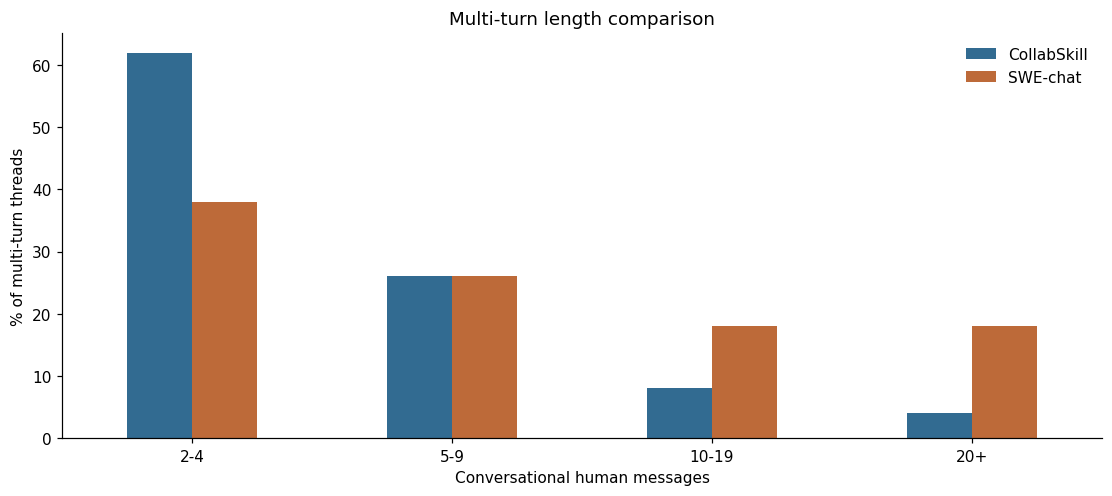

In [3]:
sample_summary = []
for name, frame in samples.items():
    for turn, group in frame.groupby("turn_type"):
        sample_summary.append(dict(dataset=name, turn_type=turn, scenarios=len(group),
            median_human_messages=group.human_messages.median(), maximum_human_messages=group.human_messages.max(),
            median_tool_events=group.tool_events.median(), total_retained_events=group.event_count.sum()))
display(pd.DataFrame(sample_summary).set_index(["dataset", "turn_type"]))
counts, percentages, fig = compare_lengths(samples, multi_only=True)
display(counts)
display(fig)
plt.close(fig)

## 2. CollabSkill

GDPval, APEX and APEX-Agents retain their source categories. Category matching is count-level matching. It does not establish causal pairs or human-validated labels. GDPval occupation labels use exact task-ID joins, while some APEX categories are inferred or provisional.

In [4]:
collab_sample = samples["CollabSkill"]
display(count_and_percent(collab_sample, "dataset").round(2))
display(collab_org.shortfall_report(collab_sample, sample_configs["CollabSkill"]))
display(collab_sample.groupby(["dataset", "native_category", "category_status", "turn_type"], dropna=False).size().rename("scenarios").to_frame())
gdp_sample = collab_sample[collab_sample.dataset.eq("gdpval_benchmark")]
occupation_balance = pd.crosstab([gdp_sample.native_category, gdp_sample.occupation], gdp_sample.turn_type).reindex(columns=["single", "multi"], fill_value=0)
occupation_balance["single minus multi"] = occupation_balance.single - occupation_balance.multi
display(occupation_balance)
display(count_and_percent(collab_sample, "agent_id").round(2))
display(collab_org.concentration_report(collab_sample).round(2))

,single n,single %,multi n,multi %
dataset,,,,
apex,5,10.0,5,10.0
apex_agents,6,12.0,6,12.0
gdpval_benchmark,39,78.0,39,78.0


,kind,dataset,category,turn_type,requested,achieved,shortfall
0,category,gdpval_benchmark,Finance and Insurance,single,6,6,0
1,category,gdpval_benchmark,Finance and Insurance,multi,6,6,0
2,category,gdpval_benchmark,Government,single,7,7,0
3,category,gdpval_benchmark,Government,multi,7,7,0
4,category,gdpval_benchmark,Health Care and Social Assistance,single,2,2,0
5,category,gdpval_benchmark,Health Care and Social Assistance,multi,2,2,0
6,category,gdpval_benchmark,Information,single,4,4,0
7,category,gdpval_benchmark,Information,multi,4,4,0
8,category,gdpval_benchmark,Manufacturing,single,3,3,0
9,category,gdpval_benchmark,Manufacturing,multi,3,3,0


scenarios
dataset          native_category                                  category_status                    turn_type           
apex             Consulting                                       source_label_via_content_crosswalk multi              2
                                                                                                     single             2
                 Finance                                          source_label_via_content_crosswalk multi              2
                                                                                                     single             2
                 Medicine                                         source_label_via_content_crosswalk multi              1
                                                                                                     single             1
apex_agents      Investment banking                               provisional_not_source_verified    multi              3
                                                                                                     single             3
                 Law                                              provisional_not_source_verified    multi              1
                                                                                                     single             1
                 Management consulting                            provisional_not_source_verified    multi              2
                                                                                                     single             2
gdpval_benchmark Finance and Insurance                            source_metadata_exact_id_join      multi              6
                                                                                                     single             6
                 Government                                       source_metadata_exact_id_join      multi              7
                                                                                                     single             7
                 Health Care and Social Assistance                source_metadata_exact_id_join      multi              2
                                                                                                     single             2
                 Information                                      source_metadata_exact_id_join      multi              4
                                                                                                     single             4
                 Manufacturing                                    source_metadata_exact_id_join      multi              3
                                                                                                     single             3
                 Professional, Scientific, and Technical Services source_metadata_exact_id_join      multi              9
                                                                                                     single             9
                 Real Estate and Rental and Leasing               source_metadata_exact_id_join      multi              1
                                                                                                     single             1
                 Retail Trade                                     source_metadata_exact_id_join      multi              4
                                                                                                     single             4
                 Wholesale Trade                                  source_metadata_exact_id_join      multi              3
                                                                                                     single             3

turn_type                                                                                            single  ...  single minus multi
native_category                                  occupation                                                  ...                    
Finance and Insurance                            Customer Service Representatives                         4  ...                   0
                                                 Financial and Investment Analysts                        2  ...                   0
Government                                       Administrative Services Managers                         3  ...                   0
                                                 Child, Family, and School Social Workers                 1  ...                   0
                                                 Compliance Officers                                      2  ...                   0
                                                 First-Line Supervisors of Police and Detectives          1  ...                   0
Health Care and Social Assistance                Medical Secretaries and Administrative Assistants        2  ...                   0
Information                                      Editors                                                  1  ...                   0
                                                 News Analysts, Reporters, and Journalists                3  ...                   0
Manufacturing                                    Shipping, Receiving, and Inventory Clerks                3  ...                   0
Professional, Scientific, and Technical Services Computer and Information Systems Managers                5  ...                   0
                                                 Project Management Specialists                           3  ...                   0
                                                 Software Developers                                      1  ...                   0
Real Estate and Rental and Leasing               Property, Real Estate, and Community Associatio...       1  ...                   0
Retail Trade                                     General and Operations Managers                          3  ...                   0
                                                 Pharmacists                                              1  ...                   0
Wholesale Trade                                  Order Clerks                                             3  ...                   0

[17 rows x 3 columns]

,single n,single %,multi n,multi %
agent_id,,,,
claude_code,1,2.0,10,20.0
codex,9,18.0,15,30.0
cowork,13,26.0,7,14.0
gemini_cli,4,8.0,10,20.0
manus,23,46.0,8,16.0


,dimension,distinct,maximum_sessions,maximum_share_pct
0,user_id,60,4,4.0
1,task_id,72,4,4.0
2,agent_id,5,31,31.0
3,split_group_id,24,10,10.0


## 3. SWE-chat

Initial prompt intent and pushback are source automated labels. Coding mode describes recorded code contribution, not requested autonomy or task quality. Logical human messages group native source fragments. Single-turn threads have no later-human-message opportunity.

In [5]:
swe_sample = samples["SWE-chat"]
for attribute in ["initial_intent", "coding_mode", "length_bin"]:
    display(count_and_percent(swe_sample, attribute, LENGTH_BINS if attribute == "length_bin" else None).round(2))
swe_saved_quota = pd.read_csv(DATA_ROOT / snapshot_pins["samples"]["SWE-chat"]["directory"] / "quota_report.csv")
display(swe_saved_quota)
print("Message-level source pushback labels, with single/multi denominators:")
display(saved_pushback(DATA_ROOT, snapshot_pins["samples"]["SWE-chat"]).round(2))
print("Later-message pushback by thread:")
display(pd.crosstab(swe_sample.turn_type, swe_sample.later_pushback_prompts.fillna(0).gt(0)))

Message-level source pushback labels, with single/multi denominators:
Later-message pushback by thread:


,single n,single %,multi n,multi %
initial_intent,,,,
Unannotated,14,28.0,14,28.0
connect,1,2.0,1,2.0
create new code,8,16.0,8,16.0
debug,5,10.0,5,10.0
git,3,6.0,3,6.0
other,6,12.0,6,12.0
refactor,4,8.0,4,8.0
test,1,2.0,1,2.0
understand,8,16.0,8,16.0


,single n,single %,multi n,multi %
coding_mode,,,,
Collaborative,10,20.0,18,36.0
Human-only,16,32.0,10,20.0
Unknown,13,26.0,7,14.0
Vibe coding,11,22.0,15,30.0


,single n,single %,multi n,multi %
length_bin,,,,
single,50,100.0,0,0.0
2-4,0,0.0,19,38.0
5-9,0,0.0,13,26.0
10-19,0,0.0,9,18.0
20+,0,0.0,9,18.0


,dimension,stratum,turn_type,requested,achieved,shortfall
0,intent,create new code,single,8,8,0
1,intent,create new code,multi,8,8,0
2,intent,understand,single,8,8,0
3,intent,understand,multi,8,8,0
4,intent,other,single,6,6,0
5,intent,other,multi,6,6,0
6,intent,debug,single,5,5,0
7,intent,debug,multi,5,5,0
8,intent,refactor,single,4,4,0
9,intent,refactor,multi,4,4,0


,single messages,single %,multi messages,multi %
prompt_pushback,,,,
non_pushback,31,62.0,289,43.26
correction,4,8.0,278,41.62
failure_report,3,6.0,28,4.19
rejection,0,0.0,14,2.10
Unannotated/conflicting,12,24.0,59,8.83


later_pushback_prompts,False,True
turn_type,,
multi,13,37
single,50,0


## 4. Six-thread midway annotation sample

Three pairs: bridal sales, UAT test planning and code review. The CollabSkill pairs share assigned task IDs. The SWE-chat pair is thematic across different projects and agents. The practice examples are exposed and must stay out of any later blind holdout, including related split groups.

Open the downloaded HTML reading page for annotation. Source-generated labels and automated outcomes are hidden in its reading views. Missing attachments or workspace context can make aspects not assessable.

In [6]:
packet = DATA_ROOT / "curated/midway-annotation-sample"
practice = pd.read_csv(packet / "scenario_manifest.csv")
assert len(practice) == 6 and practice.scenario_id.is_unique
assert practice.turn_type.value_counts().to_dict() == {"single":3,"multi":3}
all_selected = set().union(*(set(frame.scenario_id) for frame in samples.values()))
assert set(practice.scenario_id) <= all_selected
display(practice[["practice_id", "turn_type", "human_messages", "scenario_id"]])
print("Reading page: curated/midway-annotation-sample/practice_threads.html")

Reading page: curated/midway-annotation-sample/practice_threads.html


,practice_id,turn_type,human_messages,scenario_id
0,P01,single,1.0,collabskill_915dc97da5236d63ad10
1,P02,multi,3.0,collabskill_8d5fddafbc8b4a677a59
2,P07,single,1.0,collabskill_e0100d26f02187fd817d
3,P08,multi,3.0,collabskill_0e6d3450825257791df0
4,SWE-P01,single,1.0,swe_chat_59167f32cf8541e5dd07
5,SWE-P02,multi,2.0,swe_chat_53440aeae61f3ad2555d


## 5. Optional curated thread preview

Disabled by default. This preview shows at most 60 events and caps text for display. Use the complete midway reading packet for annotation. Do not use source outcome scores to guide adherence judgments.

In [7]:
SHOW_PREVIEW = False
DATASET = "SWE-chat"
SCENARIO_ID = "swe_chat_53440aeae61f3ad2555d"
if SHOW_PREVIEW:
    show_saved_thread(DATA_ROOT, snapshot_pins, DATASET, SCENARIO_ID)
else:
    print("Curated preview disabled. Use the midway packet for annotation.")

Curated preview disabled. Use the midway packet for annotation.
